# จัดทีมกีฬาสีด้วย Genetic Algorithm (GA)
**วิชา Machine Learning — บทที่ 07 Genetic Algorithms** · ทีม **Finoria**

| ชื่อ | รหัสนักศึกษา |
|---|---|
| อัมพร ชินพร | |
| กัลยรัตน์ โพธิสาร | |
| ปฏิมา ถิ่นสำราญ | 6752300461 |
| รุจิรัตน์ แสงชัย | 6752300739 |
| นัทธนัท นุ่มนวล | 6752301123 |
| ขวัญมนัส คล้ายมี | 6752301239 |

### โจทย์
ใช้ GA แบ่งพนักงานจาก `HR.csv` ออกเป็น **2 สี** โดย
1. **ยุติธรรม (Fairness)**: ทั้งสองสีมีจำนวนคน เพศ อายุ และรูปร่าง (น้ำหนัก/ส่วนสูง) ใกล้เคียงกัน
2. **สานสัมพันธ์ข้ามแผนก (Harmonize)**: ไม่มีแผนกไหนกองรวมอยู่สีเดียว
3. แสดง **กระบวนการวิวัฒนาการ** ด้วย visualization

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, Image, display

import ga_teams as ga

# สไตล์กราฟ: ฟอนต์ไทย + สีประจำทีม
plt.rcParams.update({"font.family": "Tahoma", "axes.unicode_minus": False,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 100})
RED, BLUE, GRAY = "#d62728", "#1f77b4", "#7f7f7f"
TEAM_COLORS = [RED, BLUE]

## 1. สำรวจข้อมูล HR.csv

In [2]:
data = ga.load_hr("HR.csv")
problem = ga.Problem(data)
print(f"พนักงาน {problem.n} คน | {len(problem.depts)} แผนก")
for g in problem.genders:
    print(f"  {g}: {(data['gender'] == g).sum()} คน")
for k in ("age", "weight", "height"):
    print(f"  {k:6s}: เฉลี่ย {data[k].mean():6.1f}  ต่ำสุด {data[k].min():5.0f}  สูงสุด {data[k].max():5.0f}")

พนักงาน 358 คน | 19 แผนก
  Female: 236 คน
  Male: 122 คน
  age   : เฉลี่ย   41.2  ต่ำสุด    22  สูงสุด    60
  weight: เฉลี่ย   72.1  ต่ำสุด    38  สูงสุด   106
  height: เฉลี่ย  167.9  ต่ำสุด   142  สูงสุด   195


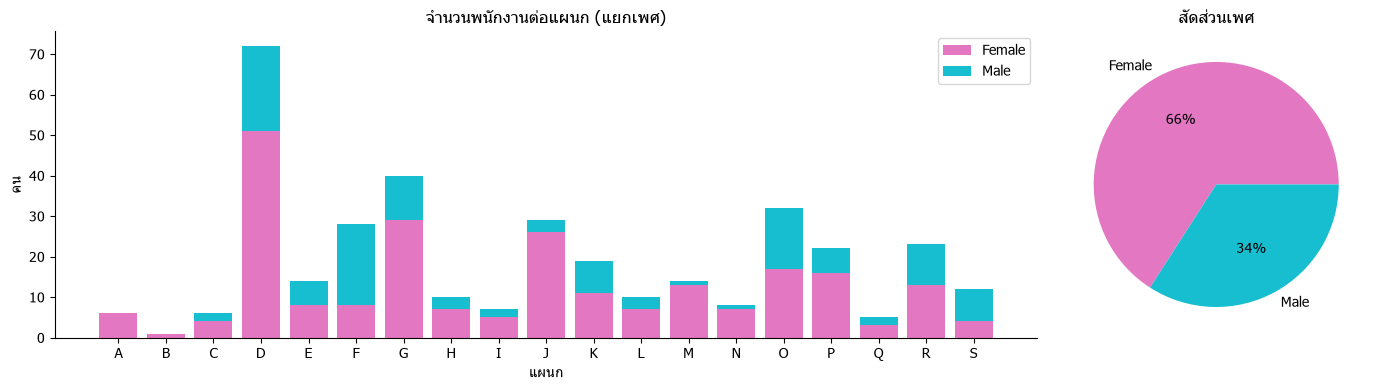

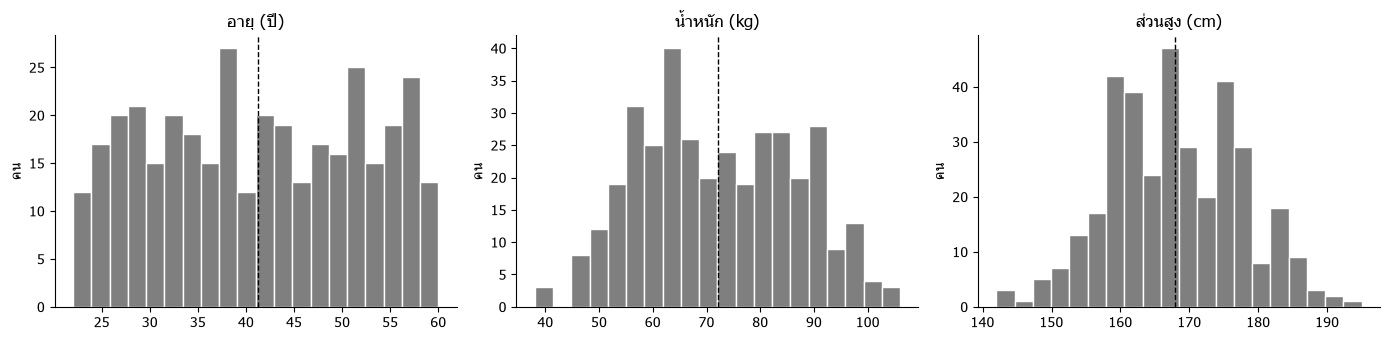

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
ax = axes[0]
x = np.arange(len(problem.depts))
male = [((data["department"] == d) & (data["gender"] == "Male")).sum() for d in problem.depts]
female = [((data["department"] == d) & (data["gender"] == "Female")).sum() for d in problem.depts]
ax.bar(x, female, color="#e377c2", label="Female")
ax.bar(x, male, bottom=female, color="#17becf", label="Male")
ax.set_xticks(x, problem.depts)
ax.set(title="จำนวนพนักงานต่อแผนก (แยกเพศ)", xlabel="แผนก", ylabel="คน")
ax.legend()

ax = axes[1]
counts = [(data["gender"] == g).sum() for g in problem.genders]
ax.pie(counts, labels=problem.genders, autopct="%1.0f%%", colors=["#e377c2", "#17becf"])
ax.set(title="สัดส่วนเพศ")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, k, label in zip(axes, ("age", "weight", "height"), ("อายุ (ปี)", "น้ำหนัก (kg)", "ส่วนสูง (cm)")):
    ax.hist(data[k], bins=20, color=GRAY, edgecolor="white")
    ax.axvline(data[k].mean(), color="k", ls="--", lw=1)
    ax.set(title=label, ylabel="คน")
plt.tight_layout()
plt.show()

**ข้อสังเกต**
- แผนก **D ใหญ่ที่สุด (72 คน ≈ 20%)** ส่วนแผนก **B มีพนักงานคนเดียว**
- พนักงานหญิงมีประมาณ 2 เท่าของชาย และบางแผนกมีแต่ผู้หญิง (เช่น A, B)
- ถ้าแบ่งทีมแบบสุ่มหรือแบ่งตามแผนก แผนกใหญ่อาจไปกองรวมอยู่สีเดียว และสองสีอาจมีสัดส่วนเพศไม่เท่ากัน

## 2. ออกแบบ Genetic Algorithm

### Chromosome
array 0/1 ยาว 358 gene: gene ที่ $i$ คือสีของพนักงานคนที่ $i$ (0 = 🔴 แดง, 1 = 🔵 น้ำเงิน)

### Fitness function (ยิ่งน้อยยิ่งดี)
$$\text{fitness} = \sum_k w_k \cdot \text{penalty}_k$$
ทุก penalty ปรับสเกลให้อยู่ในช่วง 0–1 และ **0 = ดีที่สุดเท่าที่เป็นไปได้** (กลุ่มที่มีจำนวนคี่ต่างกันอย่างน้อย 1 คนเสมอ จึงหักส่วนนั้นออก)

| เงื่อนไข | ประเภท | $w$ | วัดอะไร |
|---|---|---|---|
| `size` | ข้อบังคับ | 10 | $\left(\frac{|n_{blue}-n_{red}|}{N}\right)^2$ จำนวนคนสองสีเท่ากัน |
| `dept_cap` | ข้อบังคับ | 10 | จำนวนคนที่เกินเพดาน $\lceil n_d/2 \rceil$ รวมทุกแผนก หารด้วยค่าสูงสุดที่เป็นไปได้ |
| `gender` | ยุติธรรม | 1 | $\left(\frac{|blue_g-red_g|}{n_g}\right)^2$ เฉลี่ยทุกเพศ |
| `age` | ยุติธรรม | 1 | ครึ่งหนึ่งจากความสมดุลของช่วงอายุ (<30, 30–39, 40–49, 50+) อีกครึ่งจากผลต่างอายุเฉลี่ย (z-score)² |
| `body` | ยุติธรรม | 1 | ผลต่างน้ำหนักและส่วนสูงเฉลี่ย (z-score)² |

### ทำไมใช้ "เพดานตามสัดส่วนจริง" สำหรับการสานสัมพันธ์ข้ามแผนก
- แต่ละสีควรมีคนของแต่ละแผนก **ไม่เกินสัดส่วนที่แผนกนั้นมีในบริษัท** คือ $\lceil n_d/2 \rceil$ คน เพราะทีมละครึ่งบริษัท
- ใช้กับ**ทุกแผนก** แผนกใหญ่อย่าง D จึงครองสีใดสีหนึ่งไม่ได้ และแผนกเล็กก็ต้องกระจายไปทั้ง 2 สีด้วย
- ผลคือเพื่อนร่วมแผนกจะอยู่คนละสีกันครึ่งหนึ่ง และทุกคนได้ร่วมทีมกับคนจากแผนกอื่น
- ใช้เพดานตายตัว (เช่น 15%) ไม่ได้ เพราะแผนก D มี 20% ของบริษัท อย่างน้อยหนึ่งสีจึงต้องมีคน D ≥ 20% เสมอ

### ทำไมข้อบังคับมีน้ำหนัก 10 แต่ความยุติธรรมมีน้ำหนัก 1
ใช้หลัก **penalty method**: คำตอบที่ผิดข้อบังคับจะถูกลงโทษหนัก GA จึงหาคำตอบที่ผ่านข้อบังคับก่อน แล้วค่อยปรับความยุติธรรม (ดูได้จากกราฟในข้อ 4) ส่วนเงื่อนไขความยุติธรรมให้น้ำหนักเท่ากัน เพราะโจทย์ไม่ได้บอกว่าปัจจัยไหนสำคัญกว่า

### GA operations (ตามที่เรียนในบทที่ 07)
| ขั้นตอน | วิธี |
|---|---|
| Selection | **top-k (hard)**: เก็บครึ่งบนไว้ แล้วสร้างครึ่งล่างใหม่จากพ่อแม่ในครึ่งบน (แบบตัวอย่างของอาจารย์) · **roulette wheel (soft)**: โอกาสถูกเลือก ∝ 1/fitness และเก็บ elite 2 ตัวไว้ |
| Crossover | single-point (แบบอาจารย์) · two-point · uniform (random) |
| Mutation | อัตรา 0.8 ต่อ chromosome: สลับสีพนักงาน 1 คู่ (แดง ↔ น้ำเงิน) ขนาดทีมจึงไม่เปลี่ยน |

เพราะเก็บตัวที่ดีที่สุดไว้ทุกรุ่น ค่า best fitness จึงเป็น **monotonic** คือดีขึ้นหรือเท่าเดิม ไม่แย่ลง

## 3. รัน GA (top-k + single-point crossover แบบตัวอย่างของอาจารย์)

In [4]:
POP, GEN, SEED = 100, 300, 0
best, hist = ga.run_ga(problem, pop_size=POP, generations=GEN, selection="topk",
                       crossover_method="single", mutation_rate=0.8, seed=SEED,
                       verbose=True, print_every=20)
print("\nbest fitness ไม่เคยแย่ลง (monotonic):", bool(np.all(np.diff(hist["best"]) <= 0)))

gen    0  fitness = 0.893597
gen   20  fitness = 0.139014
gen   40  fitness = 0.007106
gen   60  fitness = 0.001746
gen   80  fitness = 0.000527
gen  100  fitness = 0.000275
gen  120  fitness = 0.000275
gen  140  fitness = 0.000275
gen  160  fitness = 0.000258
gen  180  fitness = 0.000174


gen  200  fitness = 0.000162
gen  220  fitness = 0.000071
gen  240  fitness = 0.000009
gen  260  fitness = 0.000009
gen  280  fitness = 0.000004
gen  300  fitness = 0.000004

best fitness ไม่เคยแย่ลง (monotonic): True


## 4. กระบวนการวิวัฒนาการ

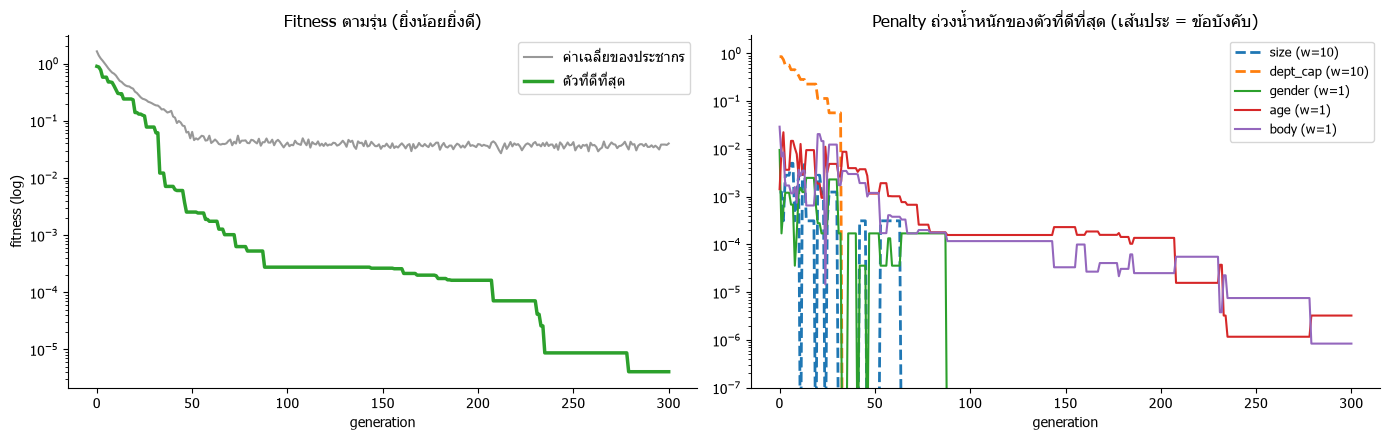

size     : รุ่น 0 = 0.00012 → รุ่น 300 = 0.000000  (เป็น 0 ครั้งแรกที่รุ่น 11)
dept_cap : รุ่น 0 = 0.08523 → รุ่น 300 = 0.000000  (เป็น 0 ครั้งแรกที่รุ่น 33)
gender   : รุ่น 0 = 0.00949 → รุ่น 300 = 0.000000  (เป็น 0 ครั้งแรกที่รุ่น 33)
age      : รุ่น 0 = 0.00143 → รุ่น 300 = 0.000003
body     : รุ่น 0 = 0.02915 → รุ่น 300 = 0.000001


In [5]:
gens = np.arange(len(hist["best"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.plot(gens, hist["mean"], color=GRAY, alpha=0.8, label="ค่าเฉลี่ยของประชากร")
ax.plot(gens, hist["best"], color="#2ca02c", lw=2.5, label="ตัวที่ดีที่สุด")
ax.set_yscale("log")
ax.set(title="Fitness ตามรุ่น (ยิ่งน้อยยิ่งดี)", xlabel="generation", ylabel="fitness (log)")
ax.legend()

ax = axes[1]
styles = {"size": ("--", 2), "dept_cap": ("--", 2), "gender": ("-", 1.5), "age": ("-", 1.5), "body": ("-", 1.5)}
for k, v in hist["parts"].items():
    ls, lw = styles[k]
    ax.plot(gens, ga.WEIGHTS[k] * v + 1e-9, ls=ls, lw=lw, label=f"{k} (w={ga.WEIGHTS[k]:g})")
ax.set_yscale("log")
ax.set_ylim(1e-7, None)
ax.set(title="Penalty ถ่วงน้ำหนักของตัวที่ดีที่สุด (เส้นประ = ข้อบังคับ)", xlabel="generation")
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig("output/fitness_evolution.png", dpi=110, bbox_inches="tight")
plt.show()

for k, v in hist["parts"].items():
    zero = np.flatnonzero(v == 0)
    print(f"{k:9s}: รุ่น 0 = {v[0]:.5f} → รุ่น {GEN} = {v[-1]:.6f}"
          + (f"  (เป็น 0 ครั้งแรกที่รุ่น {zero[0]})" if len(zero) else ""))

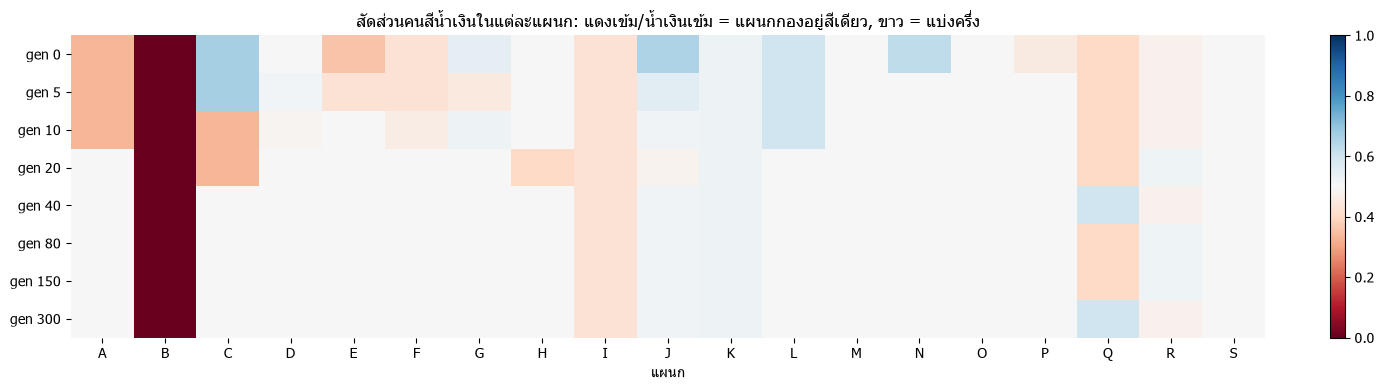

In [6]:
# สัดส่วนสีน้ำเงินของแต่ละแผนกในรุ่นต่างๆ (0.5 = แบ่งครึ่งพอดี)
snap_gens = [0, 5, 10, 20, 40, 80, 150, GEN]
mat = np.array([[hist["best_chrom"][g][data["department"] == d].mean() for d in problem.depts]
                for g in snap_gens])
fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(mat, cmap="RdBu", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(problem.depts)), problem.depts)
ax.set_yticks(range(len(snap_gens)), [f"gen {g}" for g in snap_gens])
ax.set(title="สัดส่วนคนสีน้ำเงินในแต่ละแผนก: แดงเข้ม/น้ำเงินเข้ม = แผนกกองอยู่สีเดียว, ขาว = แบ่งครึ่ง",
       xlabel="แผนก")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.025)
plt.tight_layout()
fig.savefig("output/department_evolution.png", dpi=110, bbox_inches="tight")
plt.show()

แผนก **B** มีพนักงานคนเดียว จึงอยู่ได้แค่สีเดียวเสมอ (เพดาน = 1 คน) ส่วนแผนกที่มีจำนวนคี่ เช่น I, Q จะต่างกัน 1 คนเสมอ จึงเห็นเป็นสีอ่อนๆ ในรุ่นสุดท้าย

## 5. เทียบกับการสุ่มแบ่งทีม

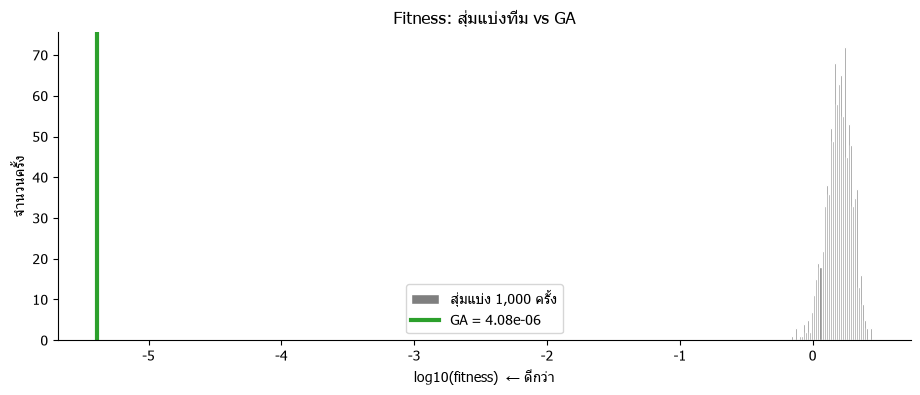

สุ่มแบ่ง: fitness เฉลี่ย 1.6066 | ดีที่สุด 0.6884 | ผ่านเพดานแผนก 0/1000 ครั้ง
GA     : fitness 4.08e-06  → ดีกว่าการสุ่มที่ดีที่สุด 168,664 เท่า


In [7]:
rng = np.random.default_rng(1)
random_pop = rng.integers(0, 2, size=(1000, problem.n))
random_fit = problem.fitness(random_pop)
random_ok = problem.penalties(random_pop)["dept_cap"] == 0

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(np.log10(random_fit), bins=40, color=GRAY, edgecolor="white", label="สุ่มแบ่ง 1,000 ครั้ง")
ax.axvline(np.log10(hist["best"][-1]), color="#2ca02c", lw=3, label=f"GA = {hist['best'][-1]:.2e}")
ax.set(title="Fitness: สุ่มแบ่งทีม vs GA", xlabel="log10(fitness)  ← ดีกว่า", ylabel="จำนวนครั้ง")
ax.legend()
fig.savefig("output/random_vs_ga.png", dpi=110, bbox_inches="tight")
plt.show()

print(f"สุ่มแบ่ง: fitness เฉลี่ย {random_fit.mean():.4f} | ดีที่สุด {random_fit.min():.4f}"
      f" | ผ่านเพดานแผนก {random_ok.sum()}/1000 ครั้ง")
print(f"GA     : fitness {hist['best'][-1]:.2e}  → ดีกว่าการสุ่มที่ดีที่สุด {random_fit.min() / hist['best'][-1]:,.0f} เท่า")

## 6. เปรียบเทียบวิธี Selection × Crossover (แบบละ 3 seed)

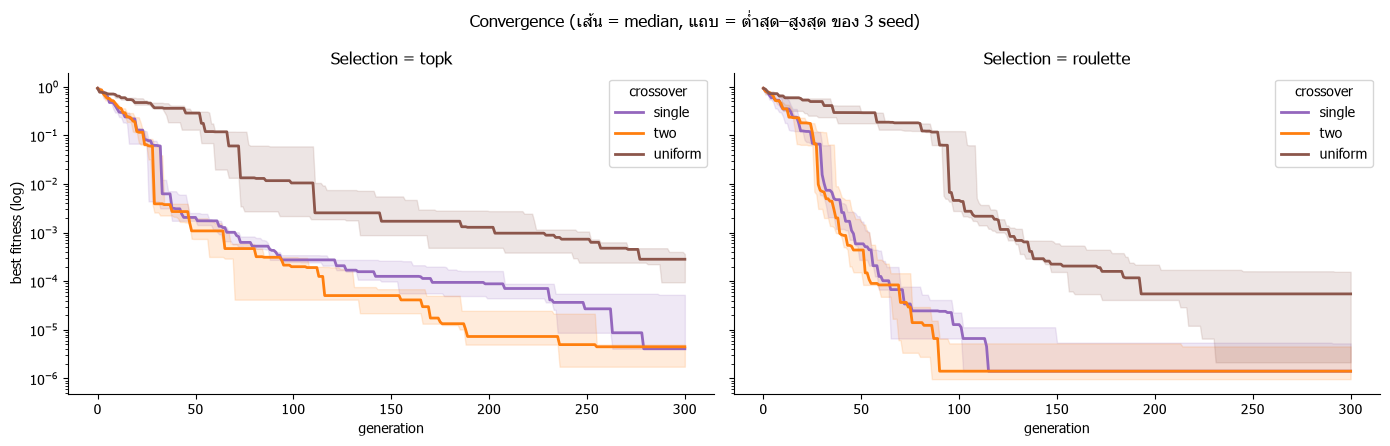

selection crossover    fitness สุดท้าย (mean ± SD)   รุ่นที่ผ่านข้อบังคับ (mean)
topk      single              2.02e-05 ± 2.3e-05                    46.0
topk      two                 3.73e-06 ± 1.4e-06                    38.3
topk      uniform             2.47e-04 ± 1.1e-04                   107.0
roulette  single              2.70e-06 ± 1.8e-06                    31.7
roulette  two                 2.31e-06 ± 1.6e-06                    35.0
roulette  uniform             7.13e-05 ± 6.4e-05                   101.7


In [8]:
configs = [(s, c) for s in ("topk", "roulette") for c in ("single", "two", "uniform")]
results = {}
for s, c in configs:
    results[(s, c)] = [ga.run_ga(problem, pop_size=POP, generations=GEN, selection=s,
                                 crossover_method=c, mutation_rate=0.8, seed=sd)[1]
                       for sd in range(3)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
colors = {"single": "#9467bd", "two": "#ff7f0e", "uniform": "#8c564b"}
for ax, s in zip(axes, ("topk", "roulette")):
    for c in ("single", "two", "uniform"):
        curves = np.array([h["best"] for h in results[(s, c)]])
        ax.plot(gens, np.median(curves, 0), color=colors[c], lw=2, label=c)
        ax.fill_between(gens, curves.min(0), curves.max(0), color=colors[c], alpha=0.15)
    ax.set_yscale("log")
    ax.set(title=f"Selection = {s}", xlabel="generation")
    ax.legend(title="crossover")
axes[0].set_ylabel("best fitness (log)")
plt.suptitle("Convergence (เส้น = median, แถบ = ต่ำสุด–สูงสุด ของ 3 seed)")
plt.tight_layout()
fig.savefig("output/method_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

print(f"{'selection':10s}{'crossover':10s}{'fitness สุดท้าย (mean ± SD)':>30s}{'รุ่นที่ผ่านข้อบังคับ (mean)':>30s}")
for s, c in configs:
    final = np.array([h["best"][-1] for h in results[(s, c)]])
    # รุ่นแรกที่ตัวที่ดีที่สุดผ่านข้อบังคับทั้งสองข้อ (size = 0 และ dept_cap = 0)
    first_ok = np.mean([np.argmax((h["parts"]["size"] == 0) & (h["parts"]["dept_cap"] == 0))
                        for h in results[(s, c)]])
    print(f"{s:10s}{c:10s}{final.mean():>18.2e} ± {final.std():.1e}{first_ok:>24.1f}")

## 7. Animation: ทีมที่ดีที่สุดในแต่ละรุ่น

บันทึก output/evolution.gif แล้ว


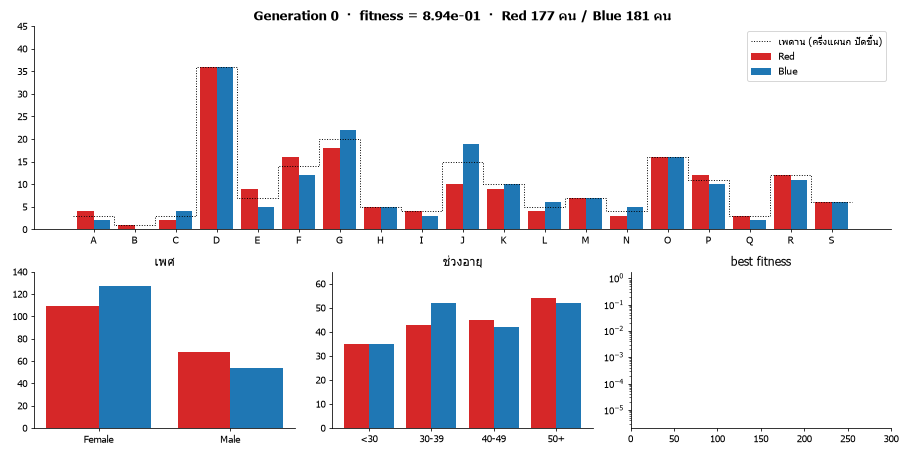

In [9]:
frame_gens = list(range(0, 30, 2)) + list(range(30, 100, 7)) + list(range(100, GEN + 1, 25))
x = np.arange(len(problem.depts))

fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1.3, 1])
ax_dept = fig.add_subplot(gs[0, :])
ax_gender = fig.add_subplot(gs[1, 0])
ax_age = fig.add_subplot(gs[1, 1])
ax_fit = fig.add_subplot(gs[1, 2])

def draw(g):
    chrom = hist["best_chrom"][g]
    for ax in (ax_dept, ax_gender, ax_age, ax_fit):
        ax.clear()
    red, blue = problem.team_counts(chrom[None, :], problem.d_onehot)
    ax_dept.bar(x - 0.2, red[0], 0.4, color=RED, label="Red")
    ax_dept.bar(x + 0.2, blue[0], 0.4, color=BLUE, label="Blue")
    ax_dept.step(np.r_[x - 0.5, x[-1] + 0.5], np.r_[problem.dept_cap, problem.dept_cap[-1]],
                 where="post", color="k", ls=":", lw=1, label="เพดาน (ครึ่งแผนก ปัดขึ้น)")
    ax_dept.set_xticks(x, problem.depts)
    ax_dept.set_ylim(0, 45)
    ax_dept.set_title(f"Generation {g}  ·  fitness = {hist['best'][g]:.2e}  ·  "
                      f"Red {int((chrom == 0).sum())} คน / Blue {int((chrom == 1).sum())} คน",
                      fontsize=13, fontweight="bold")
    ax_dept.legend(loc="upper right")

    for ax, onehot, labels, title, top in (
        (ax_gender, problem.g_onehot, problem.genders, "เพศ", 140),
        (ax_age, problem.a_onehot, ga.AGE_LABELS, "ช่วงอายุ", 65)):
        r, b = problem.team_counts(chrom[None, :], onehot)
        i = np.arange(len(labels))
        ax.bar(i - 0.2, r[0], 0.4, color=RED)
        ax.bar(i + 0.2, b[0], 0.4, color=BLUE)
        ax.set_xticks(i, labels)
        ax.set_ylim(0, top)
        ax.set_title(title)

    ax_fit.plot(gens[:g + 1], hist["best"][:g + 1], color="#2ca02c", lw=2)
    ax_fit.set_yscale("log")
    ax_fit.set_xlim(0, GEN)
    ax_fit.set_ylim(hist["best"].min() / 2, hist["best"].max() * 2)
    ax_fit.set_title("best fitness")
    fig.tight_layout()

anim = animation.FuncAnimation(fig, draw, frames=frame_gens, interval=350)
anim.save("output/evolution.gif", writer=animation.PillowWriter(fps=3), dpi=70)
plt.close(fig)
print("บันทึก output/evolution.gif แล้ว")
display(Image(filename="output/evolution.gif"))

## 8. ผลลัพธ์สุดท้าย

In [10]:
for row in ga.team_table(problem, best):
    print(" | ".join(f"{k}: {v}" for k, v in row.items()))
check = ga.check_constraints(problem, best)
print(f"\nข้อบังคับ: Red {check['red']} / Blue {check['blue']} คน · แผนกที่เกินเพดาน: {check['over_cap'] or 'ไม่มี'}")
ga.export_teams(problem, best, "output/teams.csv")
print("บันทึกรายชื่อพร้อมสีที่ output/teams.csv")

สี: Red | จำนวน: 179 | Female: 118 | Male: 61 | อายุเฉลี่ย: 41.22 | น้ำหนักเฉลี่ย: 72.1 | ส่วนสูงเฉลี่ย: 167.92 | จำนวนแผนก: 19
สี: Blue | จำนวน: 179 | Female: 118 | Male: 61 | อายุเฉลี่ย: 41.25 | น้ำหนักเฉลี่ย: 72.12 | ส่วนสูงเฉลี่ย: 167.92 | จำนวนแผนก: 18

ข้อบังคับ: Red 179 / Blue 179 คน · แผนกที่เกินเพดาน: ไม่มี
บันทึกรายชื่อพร้อมสีที่ output/teams.csv


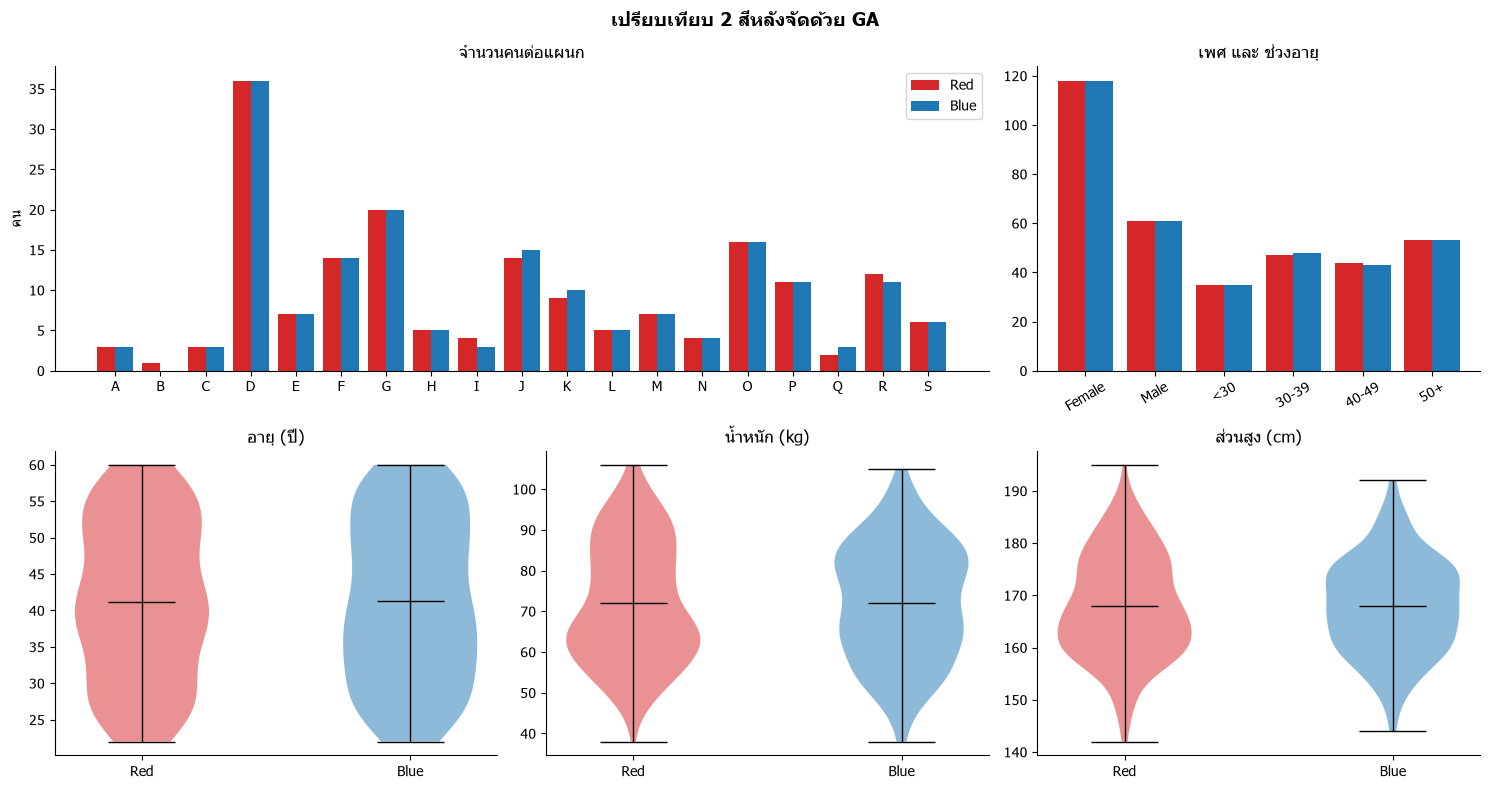

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
x = np.arange(len(problem.depts))
red, blue = problem.team_counts(best[None, :], problem.d_onehot)
ax = plt.subplot2grid((2, 3), (0, 0), colspan=2, fig=fig)
axes[0, 0].remove(); axes[0, 1].remove()
ax.bar(x - 0.2, red[0], 0.4, color=RED, label="Red")
ax.bar(x + 0.2, blue[0], 0.4, color=BLUE, label="Blue")
ax.set_xticks(x, problem.depts)
ax.set(title="จำนวนคนต่อแผนก", ylabel="คน")
ax.legend()

ax = axes[0, 2]
for t in (0, 1):
    m = best == t
    cnt = [(data["gender"][m] == g).sum() for g in problem.genders]
    cnt += [(problem.age_group[m] == i).sum() for i in range(len(ga.AGE_LABELS))]
    ax.bar(np.arange(len(cnt)) + (t - 0.5) * 0.4, cnt, 0.4, color=TEAM_COLORS[t])
ax.set_xticks(range(2 + len(ga.AGE_LABELS)), list(problem.genders) + ga.AGE_LABELS, rotation=30)
ax.set(title="เพศ และ ช่วงอายุ")

for ax, k, label in zip(axes[1], ("age", "weight", "height"), ("อายุ (ปี)", "น้ำหนัก (kg)", "ส่วนสูง (cm)")):
    parts = ax.violinplot([data[k][best == t] for t in (0, 1)], showmeans=True)
    for body, c in zip(parts["bodies"], TEAM_COLORS):
        body.set_facecolor(c)
        body.set_alpha(0.5)
    for key in ("cbars", "cmins", "cmaxes", "cmeans"):
        parts[key].set_color("k")
        parts[key].set_linewidth(1)
    ax.set_xticks([1, 2], ga.TEAM_NAMES)
    ax.set(title=label)
fig.suptitle("เปรียบเทียบ 2 สีหลังจัดด้วย GA", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig("output/final_teams.png", dpi=110, bbox_inches="tight")
plt.show()

## 9. สรุปและวิเคราะห์
> ⚠️ **ร่างจากผลที่รันได้จริง ทีมควรตรวจและเรียบเรียงด้วยคำพูดของตัวเองก่อนนำเสนอ**

**1. GA แบ่งทีมได้ตามเงื่อนไขทุกข้อ** (top-k + single-point, ประชากร 100, 300 รุ่น)
- จำนวนคน: Red 179 / Blue 179
- เพศ: หญิง 118 / ชาย 61 เท่ากันทั้งสองสี
- อายุเฉลี่ย 41.22 vs 41.25 ปี · น้ำหนัก 72.10 vs 72.12 kg · ส่วนสูง 167.92 เท่ากัน · ช่วงอายุต่างกันไม่เกิน 1 คน
- ไม่มีแผนกไหนเกินเพดาน ทุกแผนกที่มีมากกว่า 1 คนอยู่ครบทั้ง 2 สี (มีแค่แผนก B ที่มีคนเดียว)

**2. GA ดีกว่าการสุ่มอย่างชัดเจน**
- การสุ่มแบ่ง 1,000 ครั้งไม่ผ่านเพดานแผนกเลยสักครั้ง (fitness ดีที่สุด 0.688)
- GA ได้ fitness 4.08 × 10⁻⁶ ซึ่งแสดงว่า fitness function ทำหน้าที่เป็น "เข็มทิศ" ที่ชี้ทางให้ GA ได้จริง

**3. กระบวนการวิวัฒนาการ**
- best fitness ไม่เคยแย่ลง (monotonic) เพราะเก็บครึ่งบนไว้ทุกรุ่น
- ช่วงแรก penalty ของข้อบังคับที่มีน้ำหนัก 10 ลดลงก่อน: `size` เป็น 0 ที่รุ่น 11 และ `dept_cap` เป็น 0 ที่รุ่น 33 จากนั้น GA จึงค่อยๆ ปรับ `age` และ `body` ไปจนถึงรุ่น 300 ตรงตามที่ออกแบบ penalty method ไว้
- fitness เฉลี่ยของประชากรหยุดลดที่ประมาณ 0.04 เพราะ mutation อัตรา 0.8 คอยสร้างความหลากหลายในประชากรไว้

**4. เปรียบเทียบวิธี (3 seed)**
- **Crossover แบบ uniform แย่ที่สุดทั้งสอง selection**: ช้ากว่าประมาณ 3 เท่าในการผ่านข้อบังคับ (ประมาณรุ่น 100 เทียบกับ 30–46) และ fitness สุดท้ายแย่กว่า 10–100 เท่า
  - สาเหตุที่น่าจะเป็น: ใน `HR.csv` พนักงานแผนกเดียวกันเรียงติดกัน single/two-point crossover จึงส่งต่อ "ชุดของแผนก" ที่แบ่งดีแล้วไปทั้งก้อน ส่วน uniform สุ่มทีละ gene ทำให้ชุดนี้แตก
- **Roulette (soft) ได้ fitness สุดท้ายดีกว่า top-k เล็กน้อย** (2.3–2.7 × 10⁻⁶ เทียบกับ 3.7–20 × 10⁻⁶) เพราะตัวที่ fitness ไม่ดีก็ยังมีโอกาสได้เป็นพ่อแม่ ประชากรจึงหลากหลายกว่า
- ชุดที่ดีที่สุดในการทดลองนี้คือ **roulette + two-point**

**5. ข้อจำกัดและสิ่งที่ปรับปรุงได้**
- น้ำหนักของ fitness ตั้งเอง (ข้อบังคับ 10, ความยุติธรรม 1) ถ้าเปลี่ยนน้ำหนัก ผลจะเปลี่ยนตาม
- ทดลองแค่ 3 seed ยังไม่พอจะสรุปทางสถิติ
- ถ้าต้องการให้สานสัมพันธ์ข้ามแผนกมากขึ้น อาจแบ่งย่อยภายในสี (เช่น ทีมผลัด) ให้แต่ละกลุ่มย่อยคละแผนกด้วย